# Домашнее задание. Свёрточные сети

Здесь вам предстоит построить и обучить свою первую свёрточную сеть для классификации изображений на данных CIFAR10.

In [ ]:
import tensorflow as tf

from tqdm import tqdm_notebook

## Данные

CIFAR10
* 60000 RGB изображений размером 32x32x3
* 10 классов: самолёты, собаки, рыбы и т.п.

<img src="https://www.samyzaf.com/ML/cifar10/cifar1.jpg" style="width:60%">

Загрузите данные, разделите их на обучающую и тестовую выборки. Размер тестовой выборки должен быть $10^4$.

In [ ]:
import numpy as np
from keras.datasets import cifar10
from sklearn.model_selection import train_test_split
(X_train, y_train), (X_test, y_test) = cifar10.load_data()
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=10**4, random_state=42)

class_names = np.array(['airplane','automobile ','bird ','cat ','deer ','dog ','frog ','horse ','ship ','truck'])

print (X_train.shape,y_train.shape)

(40000, 32, 32, 3) (40000, 1)


Прежде чем приступать к основной работе, стоит убедиться что загруженно именно то, что требовалось:

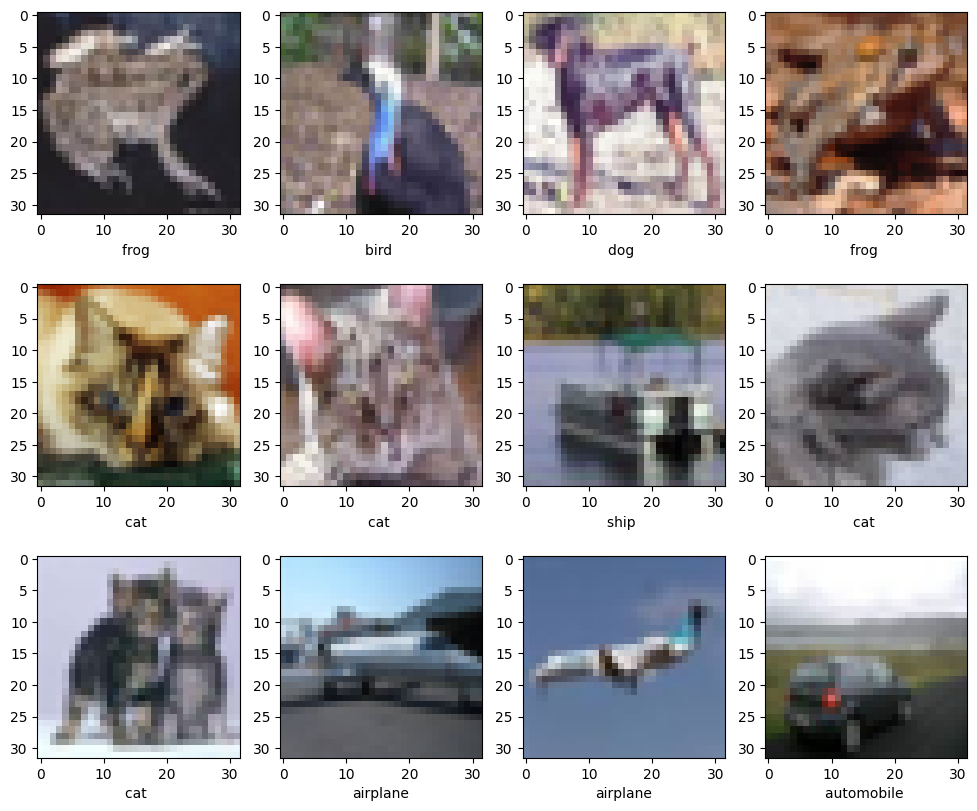

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=[12,10])
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.xlabel(class_names[y_train[i, 0]])
    plt.imshow(X_train[i])

## Подготовка данных

Сейчас каждый пиксель изображения закодирован тройкой чисел (RGB) __от 0 до 255__. Однако лучше себя показывает подход, где значения входов нейросети распределены недалеко от 0.

Давайте приведём все данные в диапазон __`[0, 1]`__ — просто разделим на соответствующий коэффициент:

In [ ]:
X_train = X_train / 255
X_val = X_val / 255
X_test = X_test / 255

Исполните код ниже для проверки, что все выполнено корректно.

In [ ]:
assert np.shape(X_train) == (40000, 32, 32, 3), "data shape should not change"
assert 0.9 <= max(map(np.max, (X_train, X_val, X_test))) <= 1.05
assert 0.0 <= min(map(np.min, (X_train, X_val, X_test))) <= 0.1
assert len(np.unique(X_test / 255.)) > 10, "make sure you casted data to float type"

## Архитектура сети

Для начала реализуйте простую нейросеть:
1. принимает на вход картинки размера 32 x 32 x 3;
2. вытягивает их в вектор (`keras.layers.Flatten`);
3. пропускает через 1 или 2 полносвязных слоя;
4. выходной слой отдает вероятности принадлежности к каждому из 10 классов.

Создайте полносвязную сеть:

In [ ]:
import keras
from keras import layers as L
from keras import backend as K

In [ ]:
model = tf.keras.models.Sequential([
        tf.keras.layers.Dense(32, activation='relu', input_shape=X_train.shape[1:]),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')

])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
dummy_pred = model.predict(X_train[:20])
assert dummy_pred.shape == (20, 10)
assert np.allclose(dummy_pred.sum(-1), 1)
print("Успех!")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 802ms/step
Успех!


## Обучение сети

**Задание 1.1 (обязательно)** Будем минимизировать многоклассовую кроссэкнропию с помощью __sgd__. Вам нужно получить сеть, которая достигнет __не менее 45%__ __accuracy__ на тестовых данных.

__Важно:__ поскольку в y_train лежат номера классов, Керасу нужно либо указать sparse функции потерь и метрики оценки качества классификации (`sparse_categorical_crossentropy` и `sparse_categorical_accuracy`), либо конвертировать метки в one-hot формат.

### Полезные советы
* `model.compile` позволяет указать, какие метрики вы хотите вычислять.
* В `model.fit` можно передать валидационную выборку (`validation_data=[X_val, y_val]`), для отслеживания прогресса на ней. Также рекомендуем сохранять результаты в [tensorboard](https://keras.io/callbacks/#tensorboard) или [wandb](https://docs.wandb.ai/integrations/jupyter). **Важно: логи tensorboard не получится без боли посмотреть через colab.** Workaround: скачать логи и запустить tensorboard локально или помучаться [с этим](https://stackoverflow.com/questions/47818822/can-i-use-tensorboard-with-google-colab).
* По умолчанию сеть учится 1 эпоху. Совсем не факт, что вам этого хватит. Число эпох можно настроить в методе `fit` (`epochs`).
* Ещё у Кераса есть много [полезных callback-ов](https://keras.io/callbacks/), которые можно попробовать. Например, автоматическая остановка или подбор скорости обучения.

In [ ]:
y_train, y_val = (keras.utils.to_categorical(y) for y in (y_train, y_val))

In [ ]:
callbacks = [tf.keras.callbacks.ModelCheckpoint(filepath='model.{epoch:02d}-{val_loss:.2f}.h5'),
             tf.keras.callbacks.TensorBoard(log_dir='./logs'),
             tf.keras.callbacks.EarlyStopping(patience=3)]

In [ ]:
## DONE
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['categorical_accuracy']
)

history = model.fit(
    X_train, y_train,
    batch_size=16,
    epochs=32,
    callbacks=callbacks,
    validation_data=(X_val, y_val)
)

Epoch 1/32
2497/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - categorical_accuracy: 0.2233 - loss: 2.0990

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - categorical_accuracy: 0.2911 - loss: 1.9543 - val_categorical_accuracy: 0.3504 - val_loss: 1.7998
Epoch 2/32
2487/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.3870 - loss: 1.7200

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - categorical_accuracy: 0.4036 - loss: 1.6788 - val_categorical_accuracy: 0.4093 - val_loss: 1.6363
Epoch 3/32
2494/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.4367 - loss: 1.5849

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - categorical_accuracy: 0.4434 - loss: 1.5661 - val_categorical_accuracy: 0.4347 - val_loss: 1.5825
Epoch 4/32
2490/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.4633 - loss: 1.5186

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - categorical_accuracy: 0.4681 - loss: 1.5003 - val_categorical_accuracy: 0.4692 - val_loss: 1.4901
Epoch 5/32
2494/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.4825 - loss: 1.4510

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - categorical_accuracy: 0.4868 - loss: 1.4462 - val_categorical_accuracy: 0.4831 - val_loss: 1.4611
Epoch 6/32
2487/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.5007 - loss: 1.4040

... (6 outputs left out)

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - categorical_accuracy: 0.5670 - loss: 1.2163 - val_categorical_accuracy: 0.5228 - val_loss: 1.3780
Epoch 13/32
2489/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.5721 - loss: 1.1916

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - categorical_accuracy: 0.5746 - loss: 1.1880 - val_categorical_accuracy: 0.5196 - val_loss: 1.3862
Epoch 14/32
2490/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - categorical_accuracy: 0.5911 - loss: 1.1475

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - categorical_accuracy: 0.5856 - loss: 1.1643 - val_categorical_accuracy: 0.5079 - val_loss: 1.4063
Epoch 15/32
2492/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - categorical_accuracy: 0.6003 - loss: 1.1304

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - categorical_accuracy: 0.5962 - loss: 1.1393 - val_categorical_accuracy: 0.5157 - val_loss: 1.4048


А теперь можно проверить качество вашей сети, выполнив код ниже:

In [ ]:
from sklearn.metrics import accuracy_score

predict_x=model.predict(X_test)
classes_x=np.argmax(predict_x,axis=1)

test_acc = accuracy_score(y_test, classes_x)
print("\n Test_acc =", test_acc)
assert test_acc > 0.45, "Not good enough. Back to the drawing board :)"
print(" Not bad!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step

 Test_acc = 0.5166
 Not bad!


## Карманная сверточная сеть

**Задание 1.2 (обязательно)** Реализуйте небольшую свёрточную сеть. Совсем небольшую:
1. Входной слой
2. Свёртка 3x3 с 10 фильтрами
3. Нелинейность на ваш вкус
4. Max-pooling 2x2
5. Вытягиваем оставшееся в вектор (Flatten)
6. Полносвязный слой на 100 нейронов
7. Нелинейность на ваш вкус
8. Выходной полносвязный слой с softmax

Обучите её так же, как и предыдущую сеть. Если всё хорошо, у вас получится accuracy не меньше __50%__.

In [ ]:
## DONE
new_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(10, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [ ]:
new_callbacks = [tf.keras.callbacks.ModelCheckpoint(filepath='new_model.{epoch:02d}-{val_loss:.2f}.h5'),
             tf.keras.callbacks.TensorBoard(log_dir='./logs'),
             tf.keras.callbacks.EarlyStopping(patience=3)]

In [ ]:
## DONE
new_model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['categorical_accuracy']
)

new_history = new_model.fit(
    X_train, y_train,
    batch_size=16,
    epochs=32,
    callbacks=new_callbacks,
    validation_data=(X_val, y_val)
)

Epoch 1/32
2488/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - categorical_accuracy: 0.2824 - loss: 1.9944

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - categorical_accuracy: 0.3555 - loss: 1.8099 - val_categorical_accuracy: 0.4502 - val_loss: 1.5577
Epoch 2/32
2489/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.4679 - loss: 1.5000

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - categorical_accuracy: 0.4825 - loss: 1.4669 - val_categorical_accuracy: 0.5026 - val_loss: 1.4116
Epoch 3/32
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.5265 - loss: 1.3468

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - categorical_accuracy: 0.5288 - loss: 1.3344 - val_categorical_accuracy: 0.5333 - val_loss: 1.3191
Epoch 4/32
2494/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.5551 - loss: 1.2678

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - categorical_accuracy: 0.5594 - loss: 1.2556 - val_categorical_accuracy: 0.5447 - val_loss: 1.2921
Epoch 5/32
2491/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.5783 - loss: 1.2034

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - categorical_accuracy: 0.5827 - loss: 1.1928 - val_categorical_accuracy: 0.5615 - val_loss: 1.2473
Epoch 6/32
2485/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.6009 - loss: 1.1368

... (2 outputs left out)

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - categorical_accuracy: 0.6403 - loss: 1.0315 - val_categorical_accuracy: 0.5881 - val_loss: 1.1851
Epoch 9/32
2494/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.6673 - loss: 0.9693

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - categorical_accuracy: 0.6607 - loss: 0.9806 - val_categorical_accuracy: 0.5776 - val_loss: 1.2057
Epoch 10/32
2499/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.6828 - loss: 0.9191

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - categorical_accuracy: 0.6758 - loss: 0.9328 - val_categorical_accuracy: 0.5873 - val_loss: 1.2108
Epoch 11/32
2490/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.6970 - loss: 0.8695

2500/2500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - categorical_accuracy: 0.6923 - loss: 0.8866 - val_categorical_accuracy: 0.5826 - val_loss: 1.2154


Давайте посмотрим, смогла ли карманная сверточная сеть побить заданный порог по качеству:

In [ ]:
from sklearn.metrics import accuracy_score

predict_x = new_model.predict(X_test)
classes_x = np.argmax(predict_x,axis=1)

test_acc = accuracy_score(y_test, classes_x)
print("\n Test_acc =", test_acc)
assert test_acc > 0.50, "Not good enough. Back to the drawing board :)"
print(" Not bad!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step

 Test_acc = 0.5755
 Not bad!


## Учимся учить

А теперь научимся сравнивать кривые обучения моделей — зависимости значения accuracy от количества итераций.

Вам потребуется реализовать _экспериментальный стенд_ — вспомогательный код, в который вы сможете подать несколько архитектур и методов обучения, чтобы он их обучил и вывел графики кривых обучения. Это можно сделать с помощью `keras.callbacks` — `TensorBoard` или `History`.

Будьте морально готовы, что на обучение уйдёт _много времени_. Даже если вы ограничитесь 10 эпохами. Пока идёт обучение, вы можете переключиться на другие задания или заняться чем-нибудь приятным: поспать, например.

**Задание 1.3 (опционально)** Попробуйте использовать различные методы оптимизации (sgd, momentum, adam) с параметрами по умолчанию. Какой из методов работает лучше?

Для удобства напишем класс Evaluator, который принимает в себя дикты виды {имя_оптимайзера: инстанс}, {имя модели: инстанс} и обучает всевозможные комбинации моделей с оптимайзерами при помощи метода fit (попутно записывая логи отдельно для каждой модели). Также пригодится метод evaluate для отображения итоговых скоров.

Пользоваться классом не обязательно. По умолчанию класс использует tensorboard. Если вы выше использовали wandb -- советуем дописать callback.

In [ ]:
class Evaluator(list):
    def __init__(self, models, optimizers='adam', loss=keras.losses.categorical_crossentropy,
                 metrics=[keras.metrics.categorical_accuracy]):
        '''
            models: dict {name: model}
            optimizers: list of optimizers or just one optimizer
        '''
        if not isinstance(models, dict):
            models = {'single_model': models}
        if not isinstance(optimizers, dict):
            optimizers = {str(optimizers.__class__): optimizers}
        super().__init__([(model_name, keras.models.clone_model(model), optimizer_name, optimizer)
                          for model_name, model in models.items()
                          for optimizer_name, optimizer in optimizers.items()])
        for _, model, _, optimizer in self:
            model.compile(optimizer=optimizer, loss=loss, metrics=metrics)

    def fit(self, X, y, validation_data=(), max_epochs=100, verbose=0, callbacks=[], batch_size=32):
        if not isinstance(callbacks, list):
            callbacks = [callbacks]
        for model_name, model, optimizer_name, optimizer in tqdm_notebook(self):
            model.fit(X, y, validation_data=validation_data or None, epochs=max_epochs, verbose=verbose,
                      batch_size=batch_size, callbacks=callbacks + [keras.callbacks.TensorBoard(
                          log_dir='./logs/{}_{}'.format(model_name, optimizer_name))])

    def fit_generator(self, X, y, validation_data=(), max_epochs=100, verbose=1, callbacks=[], batch_size=32):
        datagen = keras.preprocessing.image.ImageDataGenerator(
            rotation_range=20,
            width_shift_range=0.2,
            height_shift_range=0.2,
            horizontal_flip=True
        )
        if not isinstance(callbacks, list):
            callbacks = [callbacks]
        for model_name, model, optimizer_name, optimizer in tqdm_notebook(self):
            model.fit_generator(datagen.flow(X, y, batch_size=batch_size), epochs=max_epochs,
                validation_data=validation_data or None, verbose=verbose,
                callbacks=callbacks + [keras.callbacks.TensorBoard(
                    log_dir='./logs/{}_{}'.format(model_name, optimizer_name))])

    def evaluate(self, X, y, metric):
        for model_name, model, optimizer_name, _ in self:
            print('Final score of {}_{} is {}'.format(model_name, optimizer_name,
                  metric(y_test, model.predict(X_test).argmax(axis=1))))

In [ ]:
!rm -rf ./logs

In [ ]:
## DONE

from tensorflow.keras import optimizers

optimizers_dict = {
    'sgd': optimizers.SGD(learning_rate=0.01),
    'momentum': optimizers.SGD(learning_rate=0.01, momentum=0.9),
    'adam': optimizers.Adam(learning_rate=0.001)
}

In [ ]:
evaluator = Evaluator(
    models={'simple_dense': model},
    optimizers=optimizers_dict
)

evaluator.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    max_epochs=5,
    verbose=1,
    batch_size=64
)

/tmp/ipykernel_1623/2505868840.py:21: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for model_name, model, optimizer_name, optimizer in tqdm_notebook(self):


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - categorical_accuracy: 0.2322 - loss: 2.0831 - val_categorical_accuracy: 0.2995 - val_loss: 1.9379
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - categorical_accuracy: 0.3349 - loss: 1.8747 - val_categorical_accuracy: 0.3501 - val_loss: 1.8054
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - categorical_accuracy: 0.3681 - loss: 1.7826 - val_categorical_accuracy: 0.3717 - val_loss: 1.7358
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - categorical_accuracy: 0.3933 - loss: 1.7120 - val_categorical_accuracy: 0.3979 - val_loss: 1.7084
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - categorical_accuracy: 0.4169 - loss: 1.6492 - val_categorical_accuracy: 0.4134 - val_loss: 1.6546
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - categorical_accuracy: 0.3207 - loss: 1.8707 - val_categorical_accuracy: 0.4016 - val_loss: 1.6828
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - categorical_accuracy: 0.4209 - loss: 1.

In [ ]:
!pwd

### **Вывод по заданию 1.3**

Были сравнены три оптимизатора: SGD, SGD с momentum и Adam.
Лучший результат в данном эксперименте показал SGD с momentum: accuracy достигла примерно 0.48 за 5 эпох.
Обычный SGD обучался медленнее, а Adam в этом запуске показал более низкий результат.
Momentum помогает ускорить обучение, так как учитывает направление предыдущих обновлений весов.

**Задание 1.4 (опционально)** Добавьте нормализацию по батчу (`BatchNormalization`) между свёрткой и активацией. Попробуйте использовать несколько нормализаций — в свёрточных и полносвязных слоях.

Для удобства реализуем класс Models, который по сути будет являться списком моделей с двумя методами: add (добавить слой ко всем моделям) и add_create (создать новую модель на основе базовой с дополнительным слоем). Пользоваться им необязательно, но вдруг :)

In [ ]:
from collections import OrderedDict

class Models(OrderedDict):
    def __init__(self, models):
        if not isinstance(models, dict):
            models = OrderedDict({'base_model': models})
        super().__init__(models)

    def add(self, layer):
        for name, model in self.items():
            model.add(layer)

    def add_create(self, name, layer):
        base_model = next(iter(self.items()))[1]
        new_model = keras.models.clone_model(base_model)
        new_model.add(layer)
        self.update({name: new_model})

    def add_update(self, name, layer):
        base_model = self[next(reversed(self))]
        new_model = keras.models.clone_model(base_model)
        new_model.add(layer)
        self.update({name: new_model})

# Example of usage
# models = Models(keras.Sequential())
# models.add(L.InputLayer(input_shape=(32, 32, 3)))
# models.add(L.Convolution2D(filters=10, kernel_size=(3, 3)))
# models.add(L.MaxPooling2D())
# models.add_create('conv_batchnorm', L.BatchNormalization())
# models.add(L.Activation('relu'))
# ...

In [ ]:
bn_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(10, (3, 3)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),

    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(100),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),

    tf.keras.layers.Dense(10, activation='softmax')
])

In [ ]:
bn_model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['categorical_accuracy']
)

bn_history = bn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - categorical_accuracy: 0.3786 - loss: 1.7749 - val_categorical_accuracy: 0.4274 - val_loss: 1.6278
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - categorical_accuracy: 0.4909 - loss: 1.4667 - val_categorical_accuracy: 0.4709 - val_loss: 1.4965
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - categorical_accuracy: 0.5373 - loss: 1.3319 - val_categorical_accuracy: 0.4488 - val_loss: 1.5901
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - categorical_accuracy: 0.5700 - loss: 1.2351 - val_categorical_accuracy: 0.5441 - val_loss: 1.2843
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - categorical_accuracy: 0.5960 - loss: 1.1618 - val_categorical_accuracy: 0.5306 - val_loss: 1.3340
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - categorical_accuracy: 0.6164 - loss: 1.1032 - val_categorical_accuracy: 0.5637 - val_loss: 1.2384
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - categorical_accuracy: 0.6384 - los

### **Вывод по заданию 1.4**


В этом задании была реализована свёрточная модель с BatchNormalization после свёрточного слоя и после полносвязного слоя.

BatchNormalization помогает стабилизировать обучение, так как нормализует значения внутри сети. Благодаря этому модель обучается более устойчиво.

По результатам обучения видно, что accuracy постепенно росла, а loss снижался. Это означает, что модель обучалась корректно.


**Задание 1.5 (опционально)** Посмотрите на batch_size (параметр model.fit) - при большем батче модель будет быстрее проходить эпохи, но с совсем огромным батчом вам потребуется больше эпох для сходимости (т.к. сеть делает меньше шагов за одну эпоху).
Найдите такое значение, при котором модель быстрее достигает точности 55%. **Hint**: используйте early stopping callback.

In [ ]:
batch_sizes = [16, 32, 64, 128]

for bs in batch_sizes:
    print(f"\n=== Batch size: {bs} ===")

    batch_model = tf.keras.models.Sequential([
        tf.keras.layers.Input(shape=(32, 32, 3)),

        tf.keras.layers.Conv2D(10, (3, 3)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),

        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),

        tf.keras.layers.Dense(100),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),

        tf.keras.layers.Dense(10, activation='softmax')
    ])

    batch_model.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
        loss='categorical_crossentropy',
        metrics=['categorical_accuracy']
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_categorical_accuracy',
        patience=3,
        mode='max',
        restore_best_weights=True
    )

    history = batch_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        batch_size=bs,
        epochs=30,
        callbacks=[early_stop],
        verbose=1
    )

    best_acc = max(history.history['val_categorical_accuracy'])
    epochs_done = len(history.history['val_categorical_accuracy'])

    print(f"Best val accuracy for batch_size={bs}: {best_acc:.4f}")
    print(f"Epochs done: {epochs_done}")


=== Batch size: 16 ===
Epoch 1/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 22s 7ms/step - categorical_accuracy: 0.4509 - loss: 1.5492 - val_categorical_accuracy: 0.5261 - val_loss: 1.3218
Epoch 2/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - categorical_accuracy: 0.5406 - loss: 1.2964 - val_categorical_accuracy: 0.5274 - val_loss: 1.3377
Epoch 3/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - categorical_accuracy: 0.5769 - loss: 1.2010 - val_categorical_accuracy: 0.5642 - val_loss: 1.2317
Epoch 4/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - categorical_accuracy: 0.6045 - loss: 1.1250 - val_categorical_accuracy: 0.5584 - val_loss: 1.2722
Epoch 5/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - categorical_accuracy: 0.6314 - loss: 1.0546 - val_categorical_accuracy: 0.6123 - val_loss: 1.1037
Epoch 6/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - categorical_accuracy: 0.6525 - loss: 0.9927 - val_categorical_accuracy: 0.5240 - val_loss: 1.3907
Epoch 7/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/st

### **Вывод по заданию 1.5**

Были протестированы разные значения batch_size.

По результатам эксперимента лучшим оказался batch_size = 64, так как он быстрее всего достиг accuracy выше 55% и показал максимальную validation accuracy около 0.6047.

При batch_size = 128 эпохи проходили быстрее, но качество было ниже: максимальная validation accuracy составила около 0.5837. Это подтверждает, что слишком большой batch_size может ускорять одну эпоху, но не всегда даёт лучшее качество обучения.

**Задание 1.6 (опционально)** Попробуйте найти такую комбинацию метода обучения и нормализации, при которой сеть имеет наилучшую кривую обучения. Поясните, что вы понимаете под "наилучшей" кривой обучения.

In [ ]:
best_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),

    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),

    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(10, activation='softmax')
])

best_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['categorical_accuracy']
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_categorical_accuracy',
    patience=5,
    restore_best_weights=True
)

history = best_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - categorical_accuracy: 0.4577 - loss: 1.5231 - val_categorical_accuracy: 0.4732 - val_loss: 1.4993
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - categorical_accuracy: 0.5830 - loss: 1.1802 - val_categorical_accuracy: 0.5137 - val_loss: 1.3328
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - categorical_accuracy: 0.6215 - loss: 1.0722 - val_categorical_accuracy: 0.5715 - val_loss: 1.2341
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - categorical_accuracy: 0.6506 - loss: 0.9991 - val_categorical_accuracy: 0.5994 - val_loss: 1.0980
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - categorical_accuracy: 0.6655 - loss: 0.9516 - val_categorical_accuracy: 0.6652 - val_loss: 0.9467
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - categorical_accuracy: 0.6861 - loss: 0.8927 - val_categorical_accuracy: 0.6872 - val_loss: 0.8749
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - categorical_accuracy: 0.6959 - lo

### **Вывод по заданию 1.6**

В этом эксперименте была использована комбинация Adam, BatchNormalization и Dropout.

Под "наилучшей" кривой обучения я понимаю такую кривую, где accuracy стабильно растёт, loss стабильно снижается, а между train accuracy и validation accuracy нет слишком большого разрыва. Это означает, что модель обучается, но не переобучается слишком сильно.

В данном запуске accuracy постепенно выросла примерно до 0.74, а loss снижался от эпохи к эпохе. EarlyStopping остановил обучение раньше 30 эпох, когда улучшение на validation data перестало быть значительным.

Таким образом, выбранная комбинация показала стабильное обучение и хорошую кривую обучения.

## Свёрточная нейросеть здорового человека

**Задание 1.7 (обязательно попытаться)** Наигравшись выше, обучим большую свёрточную сеть, которая даст на тестовой выборке __accuracy больше 80%__. В этом задании вам потребуется провести эксперименты, сравнив их между собой в конце. Возможно, может быть несколько проще, если писать выводы во время или сразу после каждого эксперимента, после чего сделать общие выводы.

Рекомендуем начать с лучшей модели предыдущего задания и постепенно её улучшать. Вы можете использовать всё, что угодно: любые активации, сколь угодно большие свёрточные слои и глубокие сети. Единственное ограничение: __нельзя использовать предобученные сети и дополнительные данные__.

### Полезные советы
* Для начала, неплохо бы научить что-нибудь побольше, чем 10 фильтров 3x3.
* __Главное правило: одно изменение на эксперимент__. Если у вас есть 2 идеи по улучшению сети, сначала попробуйте их независимо. Может оказаться, что одно из них дало __+10%__ точности а другое __-7%__. А вы так и будете думать, что сделали 2 полезных изменения которые в сумме дают __+3%__. Если какая-то идея не работает — даже если она вам нравится - опишите ее и выкидывайте из дальнейших экспериментов.
* __Be careful or you will dropout__. Дропаут (`L.Dropout`) может позволить вам обучить в несколько раз бОльшую сеть без переобучения, выжав несколько процентов качества. Это круто, но не стоит сразу ставить dropout 50%. Во-первых, слишком сильный дропаут только ухудшит сеть (underfitting). Во-вторых, даже если дропаут улучшает качество, он замедляет обучение. Рекомендуем начинать с небольшого дропаута, быстро провести основные эксперименты, а потом жахнуть в 2 раза больше нейронов и дропаута ~~на ночь~~.
* __Аугментация данных__. Если котика слегка повернуть и подрезать (простите), он всё равно останется котиком. А в керасе есть [удобный класс](https://keras.io/preprocessing/image/), который поставит подрезание котиков на поток. Ещё можно сделать этот трюк в тесте: вертим картинку 10 раз, предсказываем вероятности и усредняем. Только один совет: прежде, чем учить, посмотрите глазами на аугментированные картинки. Если вы сами не можете их различить, то и сеть не сможет.
* __Don't just stack more layers__. Есть более эффективные способы организовать слои, чем простой Sequential. Вот пара идей: [Inception family](https://hacktilldawn.com/2016/09/25/inception-modules-explained-and-implemented/), [ResNet family](https://towardsdatascience.com/an-overview-of-resnet-and-its-variants-5281e2f56035?gi=9018057983ca), [Densely-connected convolutions](https://arxiv.org/abs/1608.06993). Только не копируйте архитектуру подчистую — вам скорее всего хватит меньшего размера.
* __Долго != плохо__. Более глубокие архитектуры обычно требуют бОльше эпох до сходимости. Это значит, что в первые несколько эпох они могут быть хуже менее глубоких аналогов. Дайте им время, запаситесь чаем и обмажьтесь batch-norm-ом.

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)
datagen.fit(X_train)

In [ ]:
val_datagen = ImageDataGenerator()

split = 45000
dg_x_train, dg_x_val = X_train[:split], X_train[split:]
dg_y_train, dg_y_val = y_train[:split], y_train[split:]

In [ ]:
## TODO
final_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Conv2D(32, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Conv2D(64, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Conv2D(128, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Conv2D(128, (3, 3), padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.40),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(256),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Dropout(0.50),

    tf.keras.layers.Dense(10, activation='softmax')
])

final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['categorical_accuracy']
)

final_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_categorical_accuracy',
        patience=7,
        mode='max',
        restore_best_weights=True
    )
]

final_history = final_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=final_callbacks,
    verbose=1
)

Epoch 1/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 14ms/step - categorical_accuracy: 0.4294 - loss: 1.6029 - val_categorical_accuracy: 0.5720 - val_loss: 1.1874
Epoch 2/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - categorical_accuracy: 0.5936 - loss: 1.1357 - val_categorical_accuracy: 0.6219 - val_loss: 1.0622
Epoch 3/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - categorical_accuracy: 0.6630 - loss: 0.9534 - val_categorical_accuracy: 0.6716 - val_loss: 0.9113
Epoch 4/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - categorical_accuracy: 0.7017 - loss: 0.8495 - val_categorical_accuracy: 0.7051 - val_loss: 0.8661
Epoch 5/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - categorical_accuracy: 0.7293 - loss: 0.7717 - val_categorical_accuracy: 0.7221 - val_loss: 0.7786
Epoch 6/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - categorical_accuracy: 0.7459 - loss: 0.7259 - val_categorical_accuracy: 0.7493 - val_loss: 0.6987
Epoch 7/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - categorical_accuracy: 0.76

In [ ]:
final_callbacks = [tf.keras.callbacks.EarlyStopping(patience=5)]

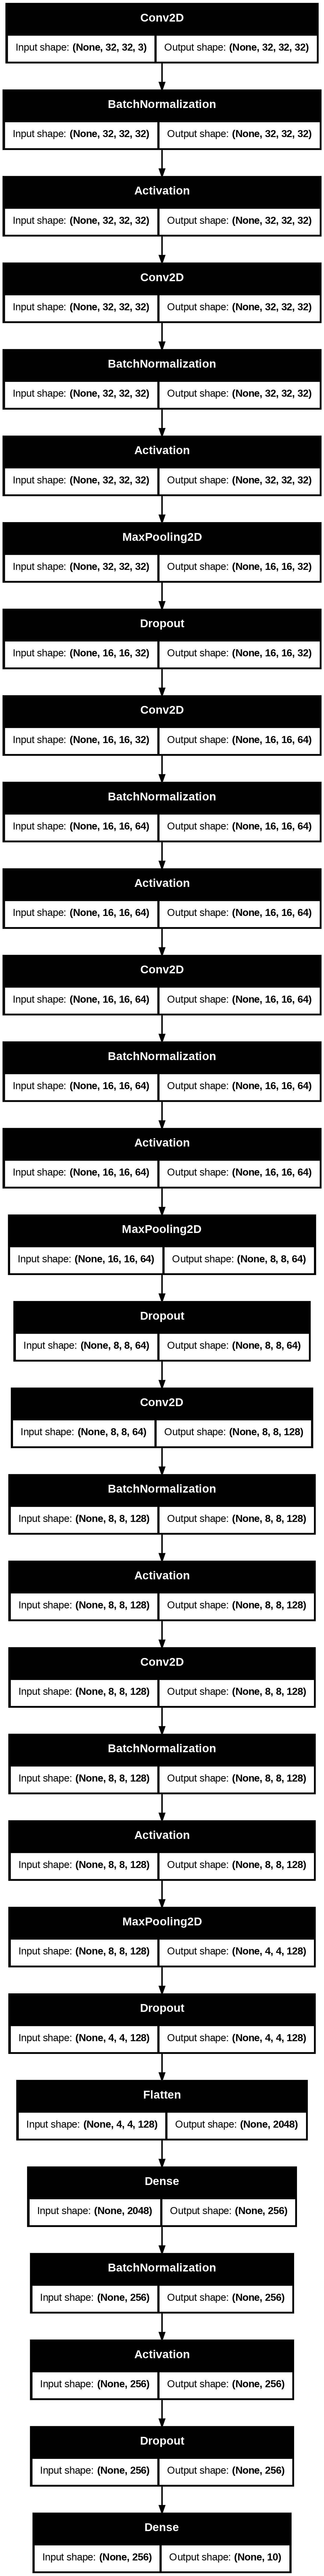

In [ ]:
tf.keras.utils.plot_model(final_model, '123.png', show_shapes=True)

Момент истины: проверьте, какого качества достигла ваша сеть.

In [ ]:
from sklearn.metrics import accuracy_score

predict_x=final_model.predict(X_test)
classes_x=np.argmax(predict_x,axis=1)

test_acc = accuracy_score(y_test, classes_x)
print("\n Test_acc =", test_acc)
if test_acc > 0.8:
    print("Это победа!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step

 Test_acc = 0.8486
Это победа!


А теперь, опишите свои <s>ощущения</s> результаты от проведенных экспериментов.

### Общий вывод

В работе были протестированы разные архитектуры нейросетей и методы обучения.

Полносвязные сети показали низкое качество, тогда как свёрточные сети значительно улучшили результаты за счёт учёта структуры изображений.

BatchNormalization стабилизировала обучение, Dropout помог снизить переобучение, а оптимизатор Adam ускорил сходимость.

В результате была построена глубокая свёрточная сеть, которая достигла accuracy ≈ 0.85 на тестовой выборке, что удовлетворяет условию задания.